# TP Probabilidad y decisiones
**LUDI, Noah** · Data Science · 05/11/2026 · Versión 1

Fuente: [Bank Marketing, UCI](https://doi.org/10.24432/C5K306), Moro, Rita y Cortez (2014). Licencia CC BY 4.0. Se usa `bank.csv`, no `bank-full.csv`.

Dependencias: `pandas`, `numpy` y `matplotlib`. Ejecutar todas las celdas en orden; la carga descarga y extrae el CSV en memoria.

In [1]:
from datetime import datetime, timezone
from hashlib import sha256
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 20)
plt.style.use("seaborn-v0_8-whitegrid")
display(pd.Series({
    "pandas": pd.__version__,
    "numpy": np.__version__,
}, name="version").to_frame())

,version
pandas,3.0.5
numpy,2.5.2


## 1. Datos y alcance

| Elemento | Definición |
|---|---|
| Unidad | Un registro de cliente en la campaña |
| Población registrada | Los registros de `bank.csv` |
| Evento S | Suscripción: `y = "yes"` |
| Denominador | Registros con `y` igual a `yes` o `no` |

La proporción del archivo completo se usa como referencia observada, sin asumir que sea la de todas las campañas futuras.

In [2]:
URL = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
with urlopen(URL, timeout=60) as respuesta:
    contenido = respuesta.read()

with ZipFile(BytesIO(contenido)) as archivo:
    contenido_bank = archivo.read("bank.zip")
with ZipFile(BytesIO(contenido_bank)) as archivo:
    nombre = next(n for n in archivo.namelist() if n.split("/")[-1] == "bank.csv")
    csv_bank = archivo.read(nombre)

datos = pd.read_csv(BytesIO(csv_bank), sep=";")
assert datos.shape == (4521, 17)
assert datos["y"].isin(["yes", "no"]).all()
assert datos["campaign"].notna().all()

display(pd.Series({
    "fuente": URL,
    "recurso": "bank.csv",
    "acceso_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "sha256_csv": sha256(csv_bank).hexdigest(),
    "filas": datos.shape[0],
    "columnas": datos.shape[1],
}).to_frame("valor"))
display(datos.head())
display(datos.dtypes.rename("tipo").to_frame())

,valor
fuente,https://archive.ics.uci.edu/static/public/222/...
recurso,bank.csv
acceso_utc,2026-11-05T17:02:24+00:00
sha256_csv,dc8d576e9bda0f41ee891251bd84bab9a39ce576cba715...
filas,4521
columnas,17


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


,tipo
age,int64
job,str
marital,str
education,str
default,str
balance,int64
housing,str
loan,str
contact,str
day,int64


## 2. Revisión y descripción

Filas duplicadas: 0


,faltantes,unknown
age,0,0
job,0,38
marital,0,0
education,0,187
default,0,0
balance,0,0
housing,0,0
loan,0,0
contact,0,1324
day,0,0


,registros,porcentaje
y,,
no,4000,88.48
yes,521,11.52


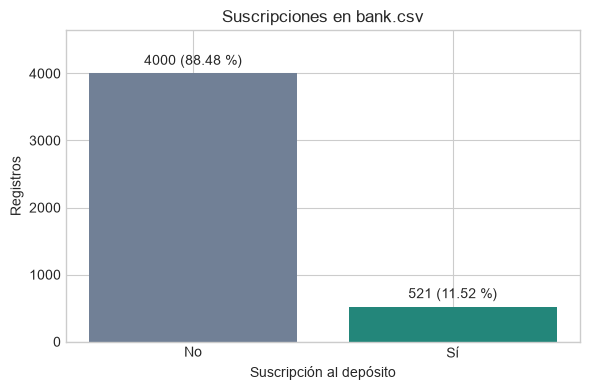

In [3]:
auditoria = pd.DataFrame({
    "faltantes": datos.isna().sum(),
    "unknown": datos.eq("unknown").sum(),
})
print("Filas duplicadas:", datos.duplicated().sum())
display(auditoria)

frecuencias = datos["y"].value_counts().reindex(["no", "yes"], fill_value=0)
tabla_y = frecuencias.rename("registros").to_frame()
tabla_y["porcentaje"] = 100 * tabla_y["registros"] / tabla_y["registros"].sum()
display(tabla_y.round(2))

fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(["No", "Sí"], tabla_y["registros"], color=["#718096", "#23867a"])
ax.bar_label(barras, labels=[
    f"{n} ({p:.2f} %)" for n, p in zip(tabla_y["registros"], tabla_y["porcentaje"])
], padding=4)
ax.set(title="Suscripciones en bank.csv", xlabel="Suscripción al depósito", ylabel="Registros")
ax.set_ylim(0, tabla_y["registros"].max() * 1.16)
plt.tight_layout()
plt.show()

La barra permite comparar suscripciones y no suscripciones. Predomina `no`. No aparecen faltantes de pandas, aunque varias columnas tienen la categoría `unknown`; no se la interpreta como un dato conocido.

,contactos
mínimo,1.0
Q1,1.0
mediana,2.0
Q3,3.0
máximo,50.0


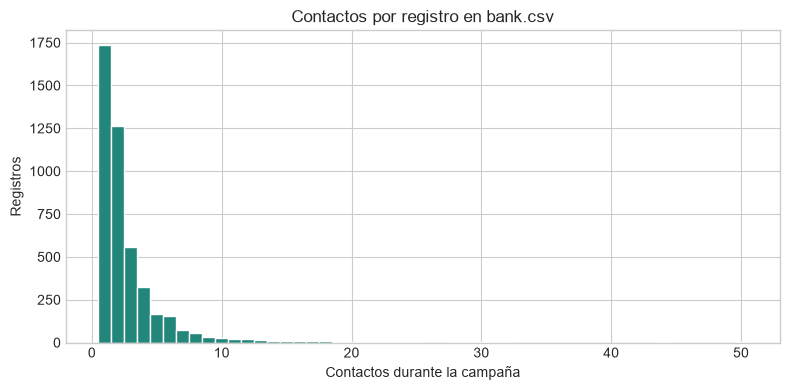

In [4]:
resumen_contactos = datos["campaign"].quantile([0, 0.25, 0.5, 0.75, 1])
resumen_contactos.index = ["mínimo", "Q1", "mediana", "Q3", "máximo"]
display(resumen_contactos.to_frame("contactos"))

fig, ax = plt.subplots(figsize=(8, 4))
limites = np.arange(0.5, datos["campaign"].max() + 1.5)
ax.hist(datos["campaign"], bins=limites, color="#23867a", edgecolor="white")
ax.set(
    title="Contactos por registro en bank.csv",
    xlabel="Contactos durante la campaña", ylabel="Registros",
)
plt.tight_layout()
plt.show()

El histograma usa un intervalo por cantidad entera de contactos y conserva la cola completa. La mayoría tiene pocos contactos: mediana 2 y Q3 igual a 3. La distribución es asimétrica hacia la derecha y llega a 50.

## 3. Proporción observada

In [5]:
validos = datos["y"].isin(["yes", "no"])
n_validos = int(validos.sum())
n_suscripciones = int(datos.loc[validos, "y"].eq("yes").sum())
p_s = n_suscripciones / n_validos
p_complemento = 1 - p_s
assert np.isclose(p_s + p_complemento, 1)

proporciones = pd.DataFrame({
    "evento": ["S: suscripción", "Complemento: no suscripción"],
    "numerador": [n_suscripciones, n_validos - n_suscripciones],
    "denominador": [n_validos, n_validos],
    "proporción": [p_s, p_complemento],
    "porcentaje": [100 * p_s, 100 * p_complemento],
})
display(proporciones.round(4))
print(f"P(S) = {n_suscripciones}/{n_validos} = {p_s:.6f} = {100 * p_s:.2f} %")
print(f"P(Sᶜ) = {n_validos - n_suscripciones}/{n_validos} = {p_complemento:.6f}")
print("Suma:", p_s + p_complemento)

,evento,numerador,denominador,proporción,porcentaje
0,S: suscripción,521,4521,0.1152,11.524
1,Complemento: no suscripción,4000,4521,0.8848,88.476


P(S) = 521/4521 = 0.115240 = 11.52 %
P(Sᶜ) = 4000/4521 = 0.884760
Suma: 1.0


## 4. Variación entre muestras

Se toman cinco muestras de 300 registros sin reemplazo, con las semillas indicadas en la consigna. Las muestras pueden compartir registros entre sí.

In [6]:
resultados = []
for semilla in [1, 2, 3, 4, 5]:
    muestra = datos.sample(n=300, replace=False, random_state=semilla)
    suscripciones = int(muestra["y"].eq("yes").sum())
    resultados.append({
        "semilla": semilla,
        "suscripciones": suscripciones,
        "registros": len(muestra),
        "proporción": suscripciones / len(muestra),
    })

muestras = pd.DataFrame(resultados)
muestras["distancia_referencia"] = (muestras["proporción"] - p_s).abs()
p_min = muestras["proporción"].min()
p_max = muestras["proporción"].max()
distancia_min = muestras["distancia_referencia"].min()
mas_cercanas = muestras.loc[
    np.isclose(muestras["distancia_referencia"], distancia_min), "semilla"
].tolist()
display(muestras.round(4))
display(Markdown(
    f"Mínimo: **{100*p_min:.2f} %**; máximo: **{100*p_max:.2f} %**. "
    f"La diferencia es **{100*(p_max-p_min):.2f} puntos porcentuales**. "
    f"Las semillas más cercanas a la referencia son **{mas_cercanas}**."
))

,semilla,suscripciones,registros,proporción,distancia_referencia
0,1,41,300,0.1367,0.0214
1,2,28,300,0.0933,0.0219
2,3,26,300,0.0867,0.0286
3,4,31,300,0.1033,0.0119
4,5,31,300,0.1033,0.0119


Mínimo: **8.67 %**; máximo: **13.67 %**. La diferencia es **5.00 puntos porcentuales**. Las semillas más cercanas a la referencia son **[4, 5]**.

Las semillas 4 y 5 empatan: ambas incluyen 31 suscripciones. Las estimaciones cambian porque cada muestra contiene distintos registros; esa variabilidad no implica que haya cambiado el archivo ni la proporción de referencia.

## 5. Decisión sobre el piloto

El escenario supone costo de 1 unidad por contacto y beneficio de 12 por suscripción. Se usa `12 × P(S) - 1` como valor esperado neto por contacto.

In [7]:
costo_contacto = 1
beneficio_suscripcion = 12
contactos_piloto = 100
valor_contacto = beneficio_suscripcion * p_s - costo_contacto
valor_piloto = contactos_piloto * valor_contacto

display(pd.Series({
    "valor esperado por contacto": valor_contacto,
    "valor esperado para 100 contactos": valor_piloto,
    "proporción de equilibrio": costo_contacto / beneficio_suscripcion,
}).round(4).to_frame("valor"))
decision = "realizar el piloto" if valor_contacto > 0 else "no realizar el piloto"
display(Markdown(
    f"Propondría **{decision}**: el valor esperado es "
    f"**{valor_contacto:.4f}** por contacto y **{valor_piloto:.2f}** "
    "para 100 contactos. Depende de que la proporción del archivo sea una "
    "referencia válida para la nueva campaña y se mantengan costos y beneficios. "
    "Es un promedio esperado, no una ganancia asegurada."
))

,valor
valor esperado por contacto,0.3829
valor esperado para 100 contactos,38.2880
proporción de equilibrio,0.0833


Propondría **realizar el piloto**: el valor esperado es **0.3829** por contacto y **38.29** para 100 contactos. Depende de que la proporción del archivo sea una referencia válida para la nueva campaña y se mantengan costos y beneficios. Es un promedio esperado, no una ganancia asegurada.

## 6. Cierre

In [8]:
display(Markdown(
    f"1. Se observan **{n_suscripciones}/{n_validos} suscripciones "
    f"({100*p_s:.2f} %)** en los registros analizados.\n\n"
    f"2. Las cinco muestras van de **{100*p_min:.2f} % a {100*p_max:.2f} %**, "
    f"una amplitud de **{100*(p_max-p_min):.2f} puntos porcentuales**.\n\n"
    f"3. Se propone **{decision}**, con un valor esperado neto de "
    f"**{valor_piloto:.2f} unidades**. El supuesto principal es que "
    "la proporción observada siga siendo útil para la campaña futura."
))

1. Se observan **521/4521 suscripciones (11.52 %)** en los registros analizados.

2. Las cinco muestras van de **8.67 % a 13.67 %**, una amplitud de **5.00 puntos porcentuales**.

3. Se propone **realizar el piloto**, con un valor esperado neto de **38.29 unidades**. El supuesto principal es que la proporción observada siga siendo útil para la campaña futura.